<a href="https://colab.research.google.com/github/Rodrigo470-1/beginning--bioinformatics/blob/main/Project_MAFFT%2Btrimal%2Bvis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Install MAFFT and TrimAl

In [5]:
# Update package lists and install MAFFT from repository
!apt-get -y update
!apt-get -qq install mafft
!mafft --version

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:6 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [82.5 kB]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:9 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,156 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates/restricted amd64 Packages [2,403 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,184 kB]


In [6]:
#Install TrimAl from author's github repo and unzip
!wget -q https://github.com/inab/trimal/releases/download/v1.5.0/trimAl_Linux_x86-64.zip
!unzip -q trimAl_Linux_x86-64.zip

#Move trimal to PATH location for easier use then cleanup files we don't need
!mv trimAl_Linux_x86-64/trimal /usr/local/bin
!rm trimAl_Linux_x86-64.zip
!rm -rf trimAl_Linux_x86-64

In [7]:
# install biopython
!pip -q install biopython pillow

In [8]:
#Check installs worked by getting version info
!mafft --version
!trimal --version
import Bio
print (Bio.__version__)

v7.505 (2022/Apr/10)

trimAl v1.5.rev0 build[2024-05-27]

1.88


In [1]:
# Upload files from your computer (select multiple)
from google.colab import files
import os, shutil, glob

INPUT_DIR = "/content/drive/MyDrive/Data" #This should point to the folder containing your data in Google Drive
os.makedirs(INPUT_DIR, exist_ok=True)

print("Select one or more protein FASTA files (.fa/.faa/.fasta):")
uploaded = files.upload()

# Move uploaded files into INPUT_DIR
for fn in uploaded.keys():
    dst = os.path.join(INPUT_DIR, fn)
    shutil.move(fn, dst)

print("\nFiles now in", INPUT_DIR)
!ls -lah /content/drive/MyDrive/Data || true


Select one or more protein FASTA files (.fa/.faa/.fasta):


Saving Hydra Vulgaris.fasta to Hydra Vulgaris.fasta
Saving Homo sapiens.fasta to Homo sapiens.fasta
Saving Amphimedon queenslandica.fasta to Amphimedon queenslandica.fasta
Saving Lottia gigantea.fasta to Lottia gigantea.fasta
Saving Octopus bimaculoiodes.fasta to Octopus bimaculoiodes.fasta
Saving Tripedalia.fasta to Tripedalia.fasta

Files now in /content/drive/MyDrive/Data
total 32K
drwxr-xr-x 2 root root 4.0K Nov 24 20:53  .
drwxr-xr-x 3 root root 4.0K Nov 24 20:52  ..
-rw-r--r-- 1 root root  641 Nov 24 20:53 'Amphimedon queenslandica.fasta'
-rw-r--r-- 1 root root  510 Nov 24 20:53 'Homo sapiens.fasta'
-rw-r--r-- 1 root root  652 Nov 24 20:53 'Hydra Vulgaris.fasta'
-rw-r--r-- 1 root root  479 Nov 24 20:53 'Lottia gigantea.fasta'
-rw-r--r-- 1 root root  332 Nov 24 20:53 'Octopus bimaculoiodes.fasta'
-rw-r--r-- 1 root root  613 Nov 24 20:53  Tripedalia.fasta


#Run MAFFT in auto mode
* **Assumes you have uploaded the P450.fasta file to this Runtime**
* MAFFT manual: https://mafft.cbrc.jp/alignment/software/manual/manual.html

In [10]:
# 1. Concatenate all your individual species FASTA files into one combined file
!cat "/content/drive/MyDrive/Data/Homo sapiens.fasta" \
     "/content/drive/MyDrive/Data/Tripedalia.fasta" \
     "/content/drive/MyDrive/Data/Octopus bimaculoiodes.fasta" \
     "/content/drive/MyDrive/Data/Hydra Vulgaris.fasta" \
     "/content/drive/MyDrive/Data/Lottia gigantea.fasta" \
     "/content/drive/MyDrive/Data/Amphimedon queenslandica.fasta" > combined_input.fasta

# 2. Run MAFFT in auto mode on the combined file
!mafft --auto combined_input.fasta > P450_aln.fasta

# 3. Print a quick confirmation
print("Alignment completed and saved to P450_aln.fasta")

outputhat23=16
treein = 0
compacttree = 0
stacksize: 8192 kb
rescale = 1
All-to-all alignment.
tbfast-pair (aa) Version 7.505
alg=L, model=BLOSUM62, 2.00, -0.10, +0.10, noshift, amax=0.0
0 thread(s)

outputhat23=16
Loading 'hat3.seed' ... 
done.
Writing hat3 for iterative refinement
rescale = 1
Gap Penalty = -1.53, +0.00, +0.00
tbutree = 1, compacttree = 0
Constructing a UPGMA tree ... 
    0 / 6
done.

Progressive alignment ... 
STEP     4 /5 
Reallocating..done. *alloclen = 2353
STEP     5 /5 
done.
tbfast (aa) Version 7.505
alg=A, model=BLOSUM62, 1.53, -0.00, -0.00, noshift, amax=0.0
1 thread(s)

minimumweight = 0.000010
autosubalignment = 0.000000
nthread = 0
randomseed = 0
blosum 62 / kimura 200
poffset = 0
niter = 16
sueff_global = 0.100000
nadd = 16
Loading 'hat3' ... done.
rescale = 1

    0 / 6
Segment   1/  1    1- 837
STEP 004-001-1  rejected.
Converged.

done
dvtditr (aa) Version 7.505
alg=A, model=BLOSUM62, 1.53, -0.00, -0.00, noshift, amax=0.0
0 thread(s)


Strategy:
 L-I

# Make a dot plot of the top 16 alignments
* 16 is arbitrary - (4x4 grid)

Saved grid -> top16_dotplots_grid.png


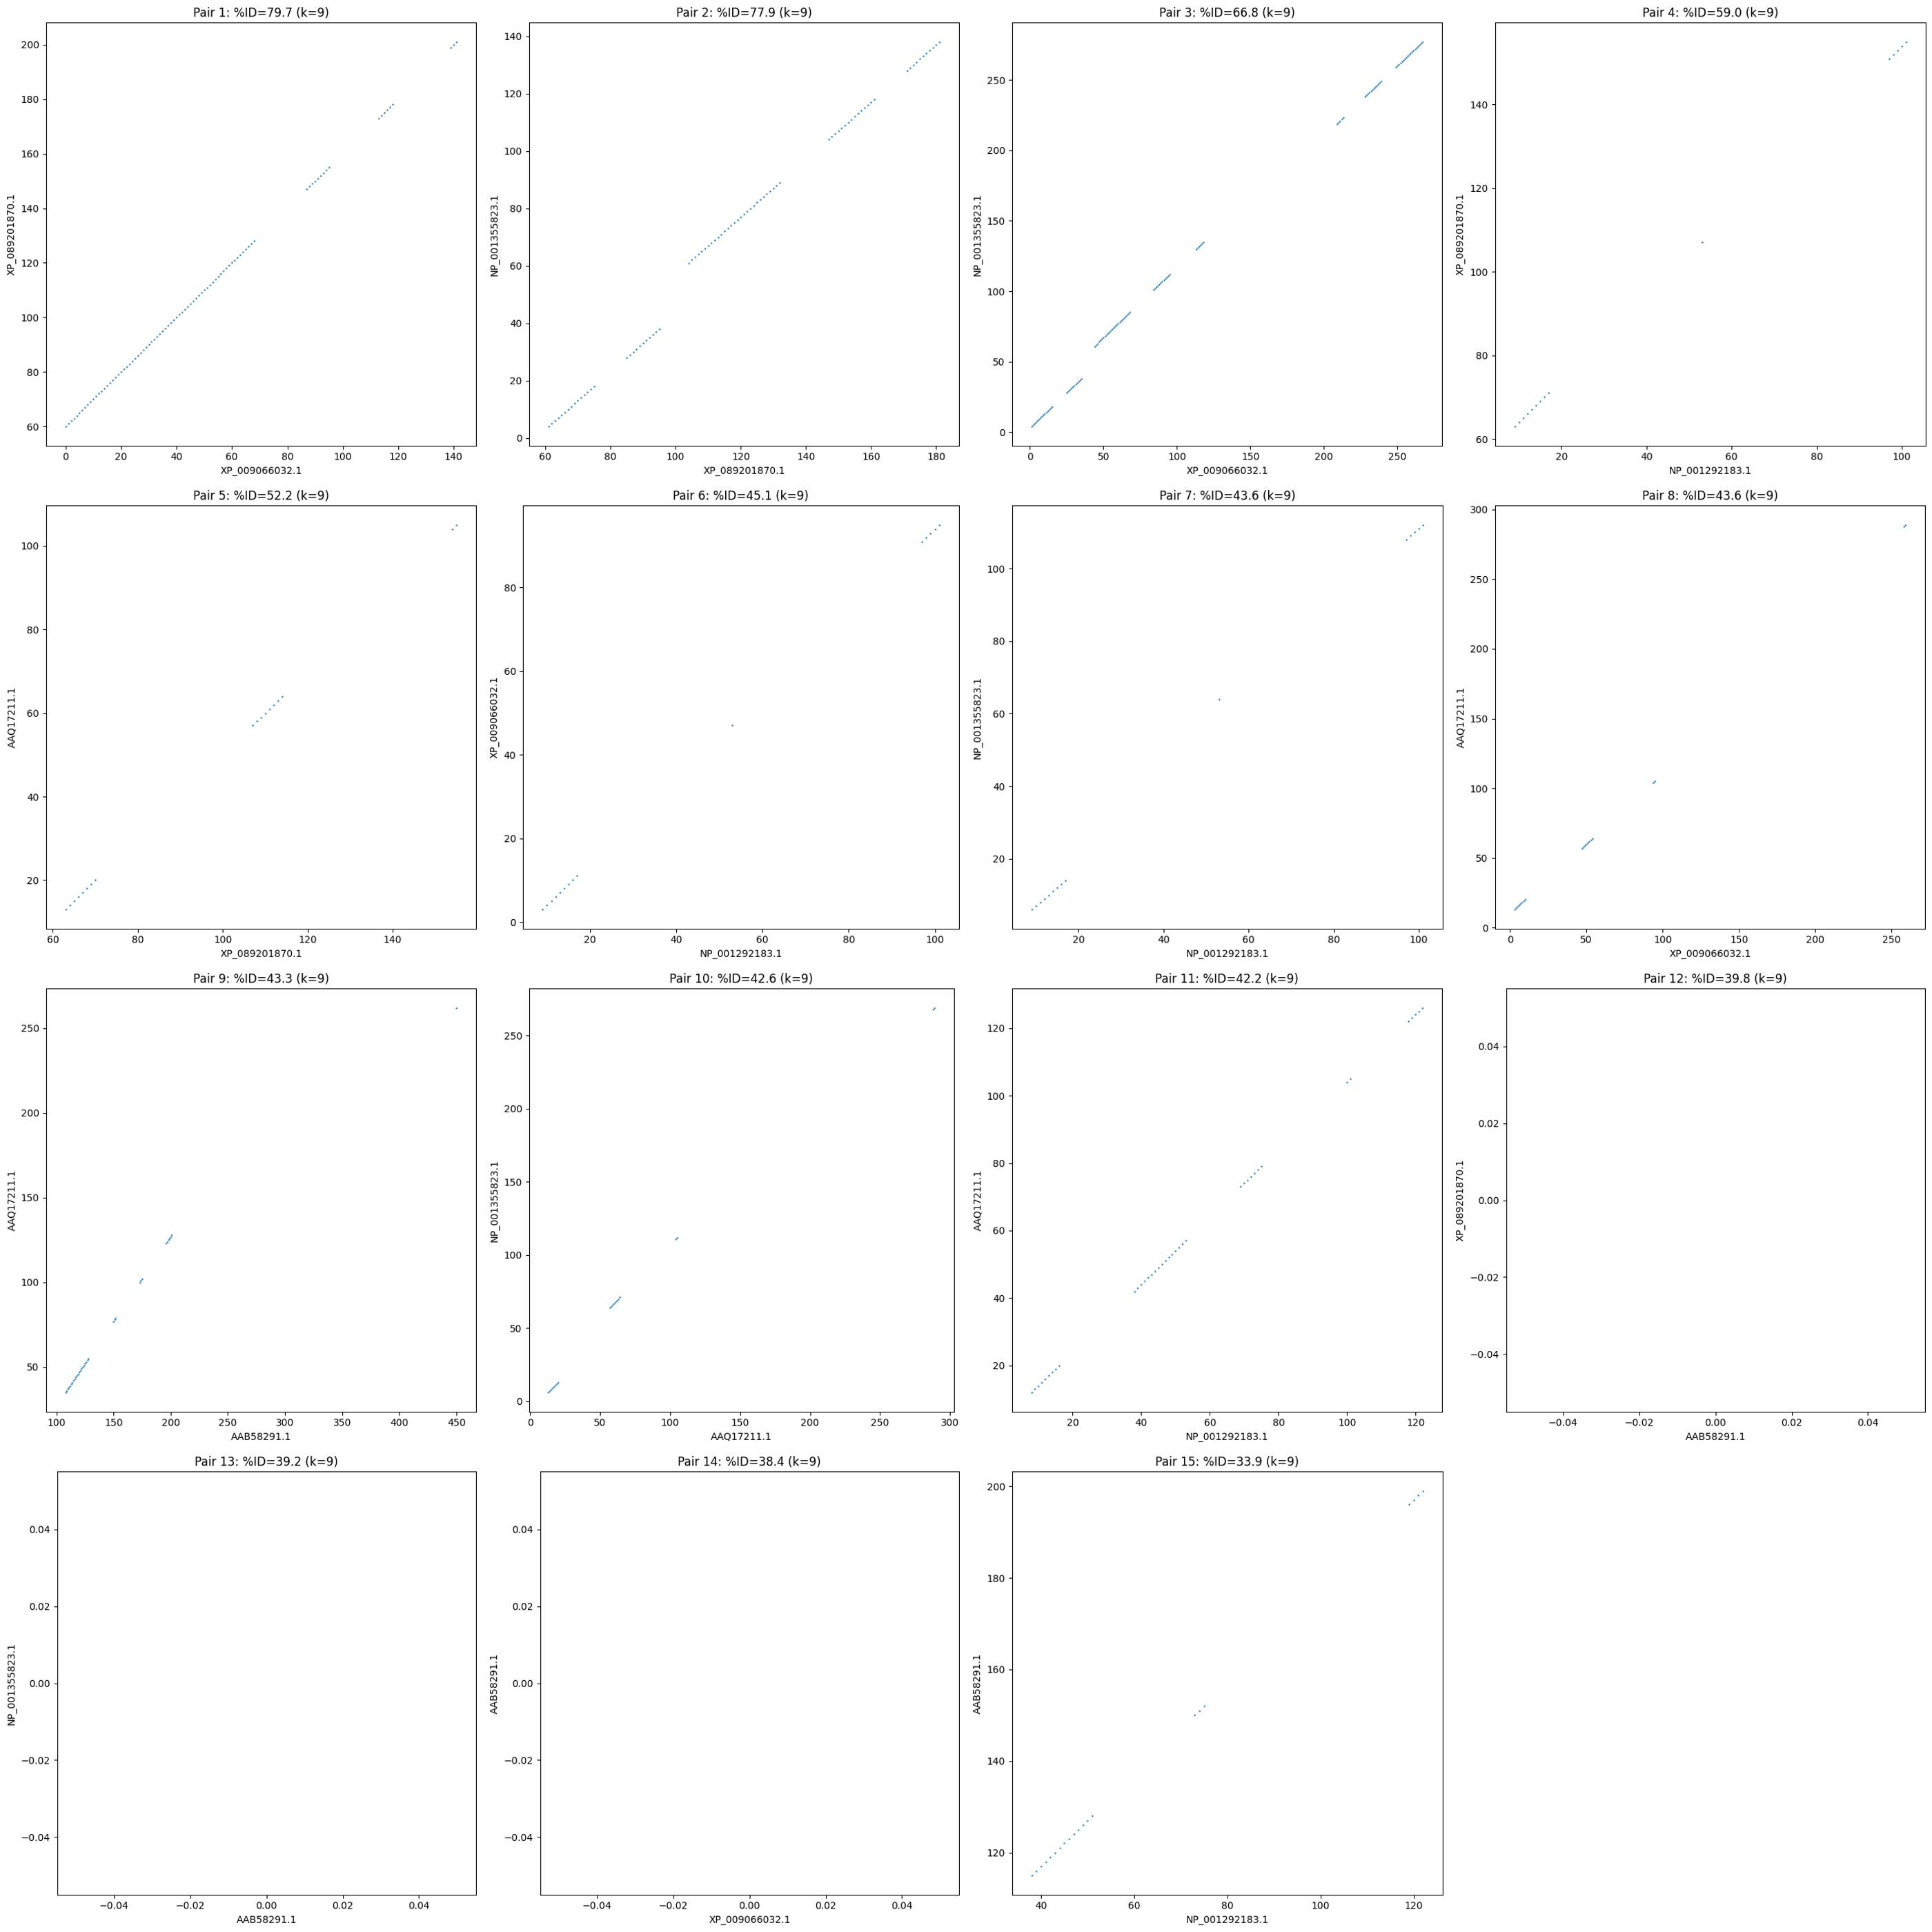

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
# Import tools
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from Bio import AlignIO
from PIL import Image
import os

msa_path = "P450_aln.fasta"   # alignment file already in /content/
msa_format = "fasta"

# ---------- params you can tweak ----------
k = 9                    # k-mer size for dot plots (larger -> cleaner diagonals)
tiles_per_row = 4
tiles_per_col = 4
tile_size_px = (700, 700)   # pixel size of each tile in the final grid
out_dir = "dotplot_tiles"
grid_out = "top16_dotplots_grid.png"
# ------------------------------------------

# Load alignment
aln = AlignIO.read(msa_path, msa_format)
N = len(aln)
ids = [rec.id for rec in aln]
seqs = [str(rec.seq) for rec in aln]
seq_bytes = [np.frombuffer(s.encode("ascii"), dtype="S1") for s in seqs]

# Pairwise identity ignoring gaps (and only comparing aligned positions)
pairs = []
for i in range(N):
    A = seq_bytes[i]
    for j in range(i+1, N):
        B = seq_bytes[j]
        valid = (A != b'-') & (B != b'-')
        denom = int(valid.sum())
        pid = float((A[valid] == B[valid]).sum())/denom if denom else 0.0
        pairs.append((pid, i, j))

# Top 16 pairs
pairs.sort(key=lambda x: x[0], reverse=True)
top_pairs = pairs[:tiles_per_row * tiles_per_col]

# Helper: dot-plot points from UNGAPPED sequences using k-mer matches
def dotplot_points(s1, s2, k):
    s1u = s1.replace('-', '')
    s2u = s2.replace('-', '')
    index = {}
    # index k-mers of s2
    L2 = len(s2u)
    for j in range(L2 - k + 1):
        km = s2u[j:j+k]
        index.setdefault(km, []).append(j)
    xs, ys = [], []
    L1 = len(s1u)
    for i in range(L1 - k + 1):
        km = s1u[i:i+k]
        js = index.get(km)
        if js:
            xs.extend(js)
            ys.extend([i]*len(js))
    return np.array(xs), np.array(ys), s1u, s2u

# Make individual tiles
os.makedirs(out_dir, exist_ok=True)
tile_paths = []
for idx, (pid, i, j) in enumerate(top_pairs, start=1):
    x, y, s1u, s2u = dotplot_points(seqs[i], seqs[j], k)
    fig = plt.figure(figsize=(tile_size_px[0]/100, tile_size_px[1]/100), dpi=100)
    plt.scatter(x, y, s=0.5)   # don't set explicit colors; keep default
    plt.xlabel(ids[j])
    plt.ylabel(ids[i])
    plt.title(f"Pair {idx}: %ID={pid*100:.1f} (k={k})")
    plt.tight_layout()
    out_path = os.path.join(out_dir, f"dotpair_{idx:02d}.png")
    plt.savefig(out_path, bbox_inches="tight")
    plt.close(fig)
    tile_paths.append(out_path)

# Stitch into a 4×4 grid
grid_w = tiles_per_row * tile_size_px[0]
grid_h = tiles_per_col * tile_size_px[1]
grid = Image.new("RGB", (grid_w, grid_h), (255, 255, 255))

for idx, path in enumerate(tile_paths):
    r = idx // tiles_per_row
    c = idx % tiles_per_row
    img = Image.open(path).resize(tile_size_px)
    grid.paste(img, (c*tile_size_px[0], r*tile_size_px[1]))

grid.save(grid_out)
print("Saved grid ->", grid_out)

#Display the graphs
from IPython.display import Image as IPyImage, display
display(IPyImage(filename=grid_out))
from google.colab import files
files.download(grid_out)

# Run TrimAl to automate trimming alignments
* https://trimal.cgenomics.org/


In [12]:
# run trimal, output the trimmed sequences and html to visualize conserved sites
# creates P450_trimmed.fasta - for input to new MSA
!trimal -in P450_aln.fasta -out P450_trimmed.fasta -htmlout trimmed.html -automated1

#Run MAFFT on trimmed sequences

In [13]:
# run mafft in auto mode
!mafft --auto P450_trimmed.fasta > P450_trimmed_aln.fasta

outputhat23=16
treein = 0
compacttree = 0
stacksize: 8192 kb
rescale = 1
All-to-all alignment.
tbfast-pair (aa) Version 7.505
alg=L, model=BLOSUM62, 2.00, -0.10, +0.10, noshift, amax=0.0
0 thread(s)

outputhat23=16
Loading 'hat3.seed' ... 
done.
Writing hat3 for iterative refinement
rescale = 1
Gap Penalty = -1.53, +0.00, +0.00
tbutree = 1, compacttree = 0
Constructing a UPGMA tree ... 
    0 / 6
done.

Progressive alignment ... 
STEP     5 /5 
done.
tbfast (aa) Version 7.505
alg=A, model=BLOSUM62, 1.53, -0.00, -0.00, noshift, amax=0.0
1 thread(s)

minimumweight = 0.000010
autosubalignment = 0.000000
nthread = 0
randomseed = 0
blosum 62 / kimura 200
poffset = 0
niter = 16
sueff_global = 0.100000
nadd = 16
Loading 'hat3' ... done.
rescale = 1

    0 / 6
Segment   1/  1    1- 217
STEP 002-003-1  identical.   
Converged.

done
dvtditr (aa) Version 7.505
alg=A, model=BLOSUM62, 1.53, -0.00, -0.00, noshift, amax=0.0
0 thread(s)


Strategy:
 L-INS-i (Probably most accurate, very slow)
 Iterat

# Generate dotplots for new trimmed MSA

Saved grid -> top16_dotplots_trimmed_grid.png


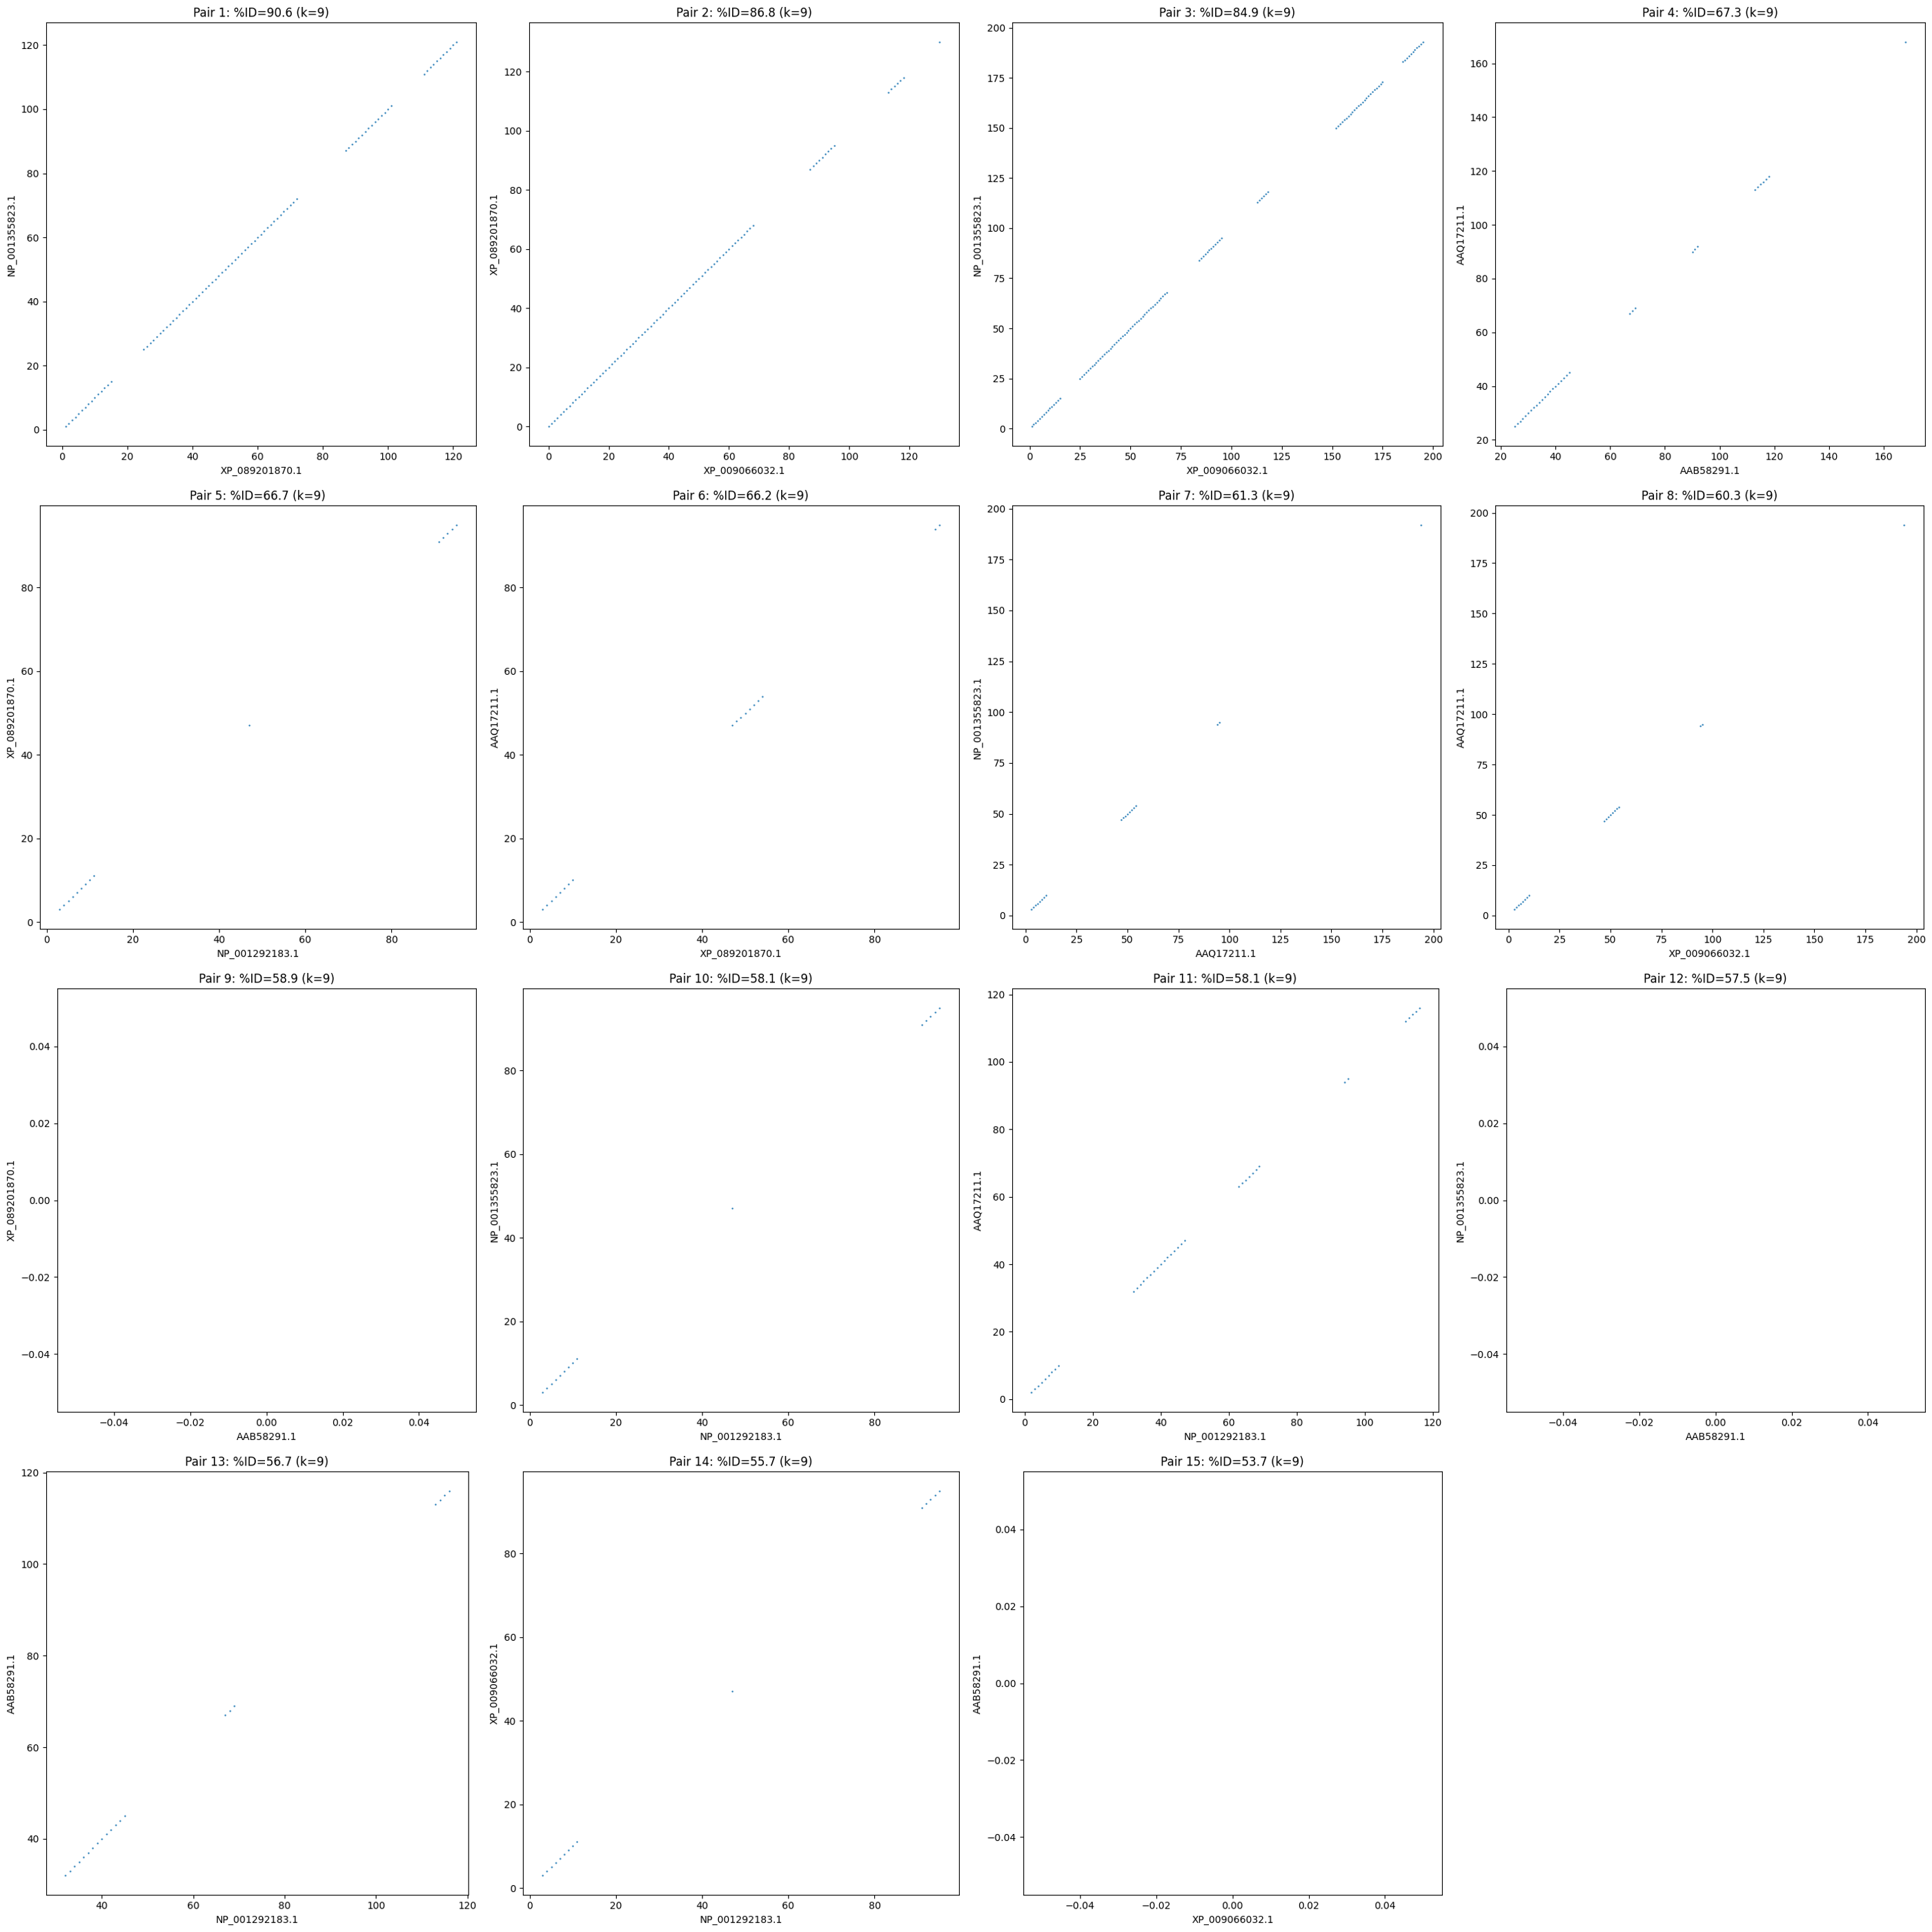

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
msa_path = "P450_trimmed_aln.fasta"   # trimmed alignment file already in /content/
msa_format = "fasta"

# ---------- params you can tweak ----------
k = 9                    # k-mer size for dot plots (larger -> cleaner diagonals)
tiles_per_row = 4
tiles_per_col = 4
tile_size_px = (700, 700)   # pixel size of each tile in the final grid
out_dir = "dotplot_tiles_trimmed"
grid_out = "top16_dotplots_trimmed_grid.png"
# ------------------------------------------

# Load alignment
aln = AlignIO.read(msa_path, msa_format)
N = len(aln)
ids = [rec.id for rec in aln]
seqs = [str(rec.seq) for rec in aln]
seq_bytes = [np.frombuffer(s.encode("ascii"), dtype="S1") for s in seqs]

# Pairwise identity ignoring gaps (and only comparing aligned positions)
pairs = []
for i in range(N):
    A = seq_bytes[i]
    for j in range(i+1, N):
        B = seq_bytes[j]
        valid = (A != b'-') & (B != b'-')
        denom = int(valid.sum())
        pid = float((A[valid] == B[valid]).sum())/denom if denom else 0.0
        pairs.append((pid, i, j))

# Top 16 pairs
pairs.sort(key=lambda x: x[0], reverse=True)
top_pairs = pairs[:tiles_per_row * tiles_per_col]

# Helper: dot-plot points from UNGAPPED sequences using k-mer matches
def dotplot_points(s1, s2, k):
    s1u = s1.replace('-', '')
    s2u = s2.replace('-', '')
    index = {}
    # index k-mers of s2
    L2 = len(s2u)
    for j in range(L2 - k + 1):
        km = s2u[j:j+k]
        index.setdefault(km, []).append(j)
    xs, ys = [], []
    L1 = len(s1u)
    for i in range(L1 - k + 1):
        km = s1u[i:i+k]
        js = index.get(km)
        if js:
            xs.extend(js)
            ys.extend([i]*len(js))
    return np.array(xs), np.array(ys), s1u, s2u

# Make individual tiles
os.makedirs(out_dir, exist_ok=True)
tile_paths = []
for idx, (pid, i, j) in enumerate(top_pairs, start=1):
    x, y, s1u, s2u = dotplot_points(seqs[i], seqs[j], k)
    fig = plt.figure(figsize=(tile_size_px[0]/100, tile_size_px[1]/100), dpi=100)
    plt.scatter(x, y, s=0.5)   # don't set explicit colors; keep default
    plt.xlabel(ids[j])
    plt.ylabel(ids[i])
    plt.title(f"Pair {idx}: %ID={pid*100:.1f} (k={k})")
    plt.tight_layout()
    out_path = os.path.join(out_dir, f"dotpair_{idx:02d}.png")
    plt.savefig(out_path, bbox_inches="tight")
    plt.close(fig)
    tile_paths.append(out_path)

# Stitch into a 4×4 grid
grid_w = tiles_per_row * tile_size_px[0]
grid_h = tiles_per_col * tile_size_px[1]
grid = Image.new("RGB", (grid_w, grid_h), (255, 255, 255))

for idx, path in enumerate(tile_paths):
    r = idx // tiles_per_row
    c = idx % tiles_per_row
    img = Image.open(path).resize(tile_size_px)
    grid.paste(img, (c*tile_size_px[0], r*tile_size_px[1]))

grid.save(grid_out)
print("Saved grid ->", grid_out)

#Display the graphs
from IPython.display import Image as IPyImage, display
display(IPyImage(filename=grid_out))
from google.colab import files
files.download(grid_out)

# Create a gene tree to show relationships among the sequences
* This code creates a circular layout tree, but that is an aesthetic choice

6 sequences; alignment length 216
Saved Newick -> gene_tree_nj.newick


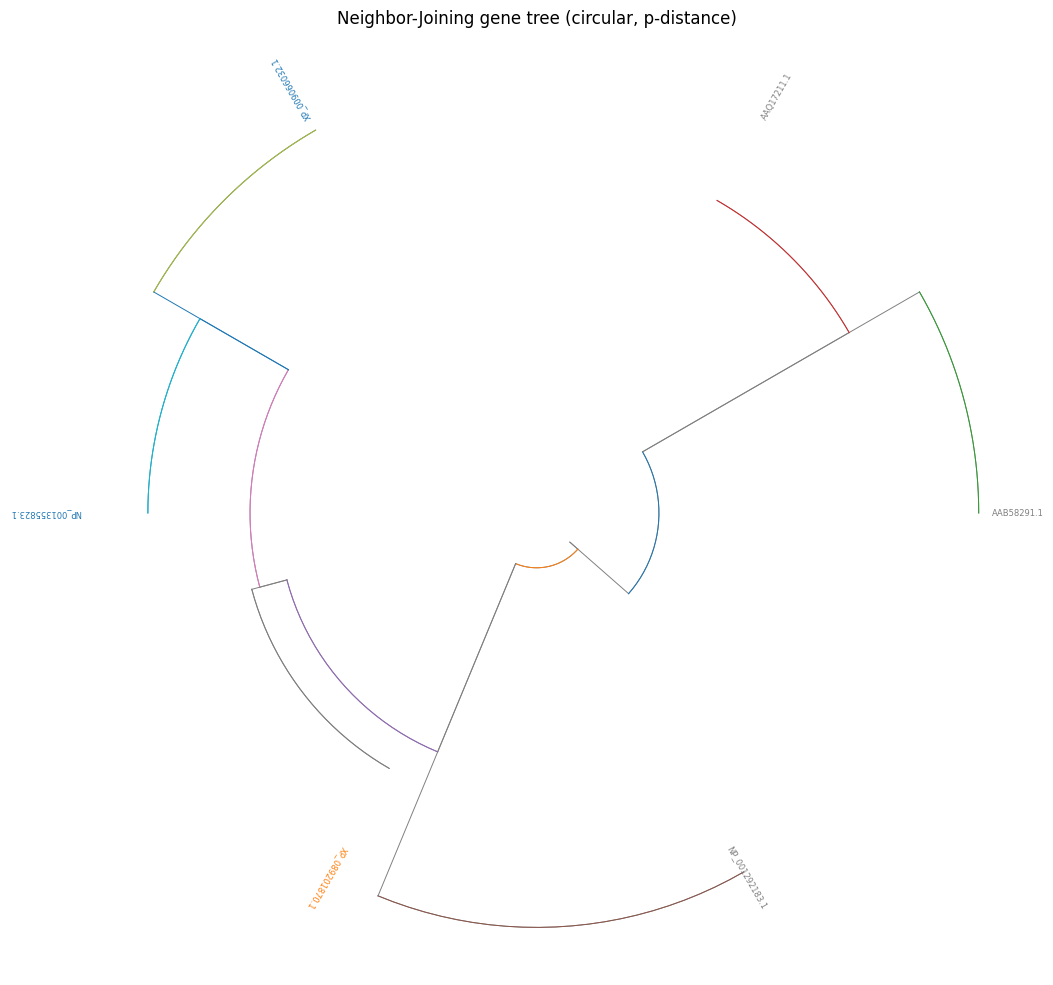

Saved PNG -> gene_tree_circular.png


In [15]:
import numpy as np
from Bio import AlignIO, Phylo
from Bio.Phylo.TreeConstruction import DistanceTreeConstructor, DistanceMatrix
import math
import matplotlib.pyplot as plt

# Load alignment
aln = AlignIO.read(msa_path, msa_format)
ids = [rec.id for rec in aln]
seqs = [np.frombuffer(str(rec.seq).encode("ascii"), dtype="S1") for rec in aln]
N = len(seqs)
print(f"{N} sequences; alignment length {aln.get_alignment_length()}")

# Fast p-distance: 1 - identity, comparing only positions where both are not gaps ('-')
def pairwise_pdist(A, B):
    valid = (A != b'-') & (B != b'-')
    denom = int(valid.sum())
    if denom == 0:
        return 1.0
    return 1.0 - float((A[valid] == B[valid]).sum()) / denom

# Build lower-triangular distance matrix
dm_mat = [[0.0]*(i+1) for i in range(N)]
for i in range(N):
    for j in range(i):
        dm_mat[i][j] = pairwise_pdist(seqs[i], seqs[j])

dm = DistanceMatrix(names=ids, matrix=dm_mat)

# Neighbor-Joining tree
constructor = DistanceTreeConstructor()
tree = constructor.nj(dm)

# Midpoint root for symmetry
try:
    tree.root_at_midpoint()
except Exception:
    pass

# Save Newick
newick_path = "gene_tree_nj.newick"
Phylo.write(tree, newick_path, "newick")
print("Saved Newick ->", newick_path)

# Compute clade depths (distance from root)
def clade_depths(clade, current=0.0, depths=None):
    if depths is None:
        depths = {}
    depths[clade] = current
    for child in clade.clades:
        bl = child.branch_length or 0.0
        clade_depths(child, current + bl, depths)
    return depths

depths = clade_depths(tree.root)
max_depth = max(depths.values()) or 1.0
def radius_of(clade):
    # map to [0.1, 1.0] for margin
    return 0.1 + 0.9 * (depths[clade] / max_depth)

# Evenly spaced leaf angles
terms = tree.get_terminals()
n_leaves = len(terms)
leaf_to_angle = {t: 2*math.pi * i / n_leaves for i, t in enumerate(terms)}

# Angle of internal nodes = circular mean of child angles
def compute_angles(clade):
    if clade.is_terminal():
        return leaf_to_angle[clade]
    child_angles = [compute_angles(c) for c in clade.clades]
    x = sum(math.cos(a) for a in child_angles) / len(child_angles)
    y = sum(math.sin(a) for a in child_angles) / len(child_angles)
    return math.atan2(y, x) % (2*math.pi)

angles = {}
def assign_angles(clade):
    angles[clade] = compute_angles(clade)
    for c in clade.clades:
        assign_angles(c)
assign_angles(tree.root)

# Draw on polar axes (one chart, no explicit colors)
fig = plt.figure(figsize=(12, 12))
ax = plt.subplot(111, projection="polar")
ax.set_axis_off()
# ----- choose which "level" to color by -----
L = 3  # e.g., root=0, children=1, etc.

# Compute topological levels (edge-count from root)
def clade_levels(clade, level=0, out=None):
    if out is None: out = {}
    out[clade] = level
    for ch in clade.clades:
        clade_levels(ch, level+1, out)
    return out

levels = clade_levels(tree.root)

# Anchor nodes at level L
anchors = [c for c, lv in levels.items() if lv == L]

# Assign colors and paint entire subtrees below each anchor
cmap = plt.get_cmap("tab10")
edge_colors = {}                         # (parent, child) -> color
anchor_color = {}                        # node at level L -> color

def paint_subtree(node, color):
    for ch in node.clades:
        edge_colors[(node, ch)] = color
        paint_subtree(ch, color)

for i, a in enumerate(anchors):
    col = cmap(i % 10)
    anchor_color[a] = col
    paint_subtree(a, col)

# (optional) make leaves’ label text match their subtree color
anchor_set = set(anchors)
def color_of_leaf(leaf):
    # path from root to leaf; first anchor we encounter decides color
    path = [tree.root] + tree.get_path(leaf)
    for n in path:
        if n in anchor_set:
            return anchor_color[n]
    return "0.5"


def draw_branch(parent, child):
    rp, rc = radius_of(parent), radius_of(child)
    ap, ac = angles[parent], angles[child]
    da = (ac - ap + math.pi) % (2*math.pi) - math.pi
    th = np.linspace(ap, ap + da, 24)

    col = edge_colors.get((parent, child), "0.5")
    ax.plot([ap, ap], [rp, rc], linewidth=0.7, color=col)
    ax.plot(th, np.full_like(th, rc), linewidth=0.7, color=col)

    # shortest arc to child angle at child radius
    da = (ac - ap + math.pi) % (2*math.pi) - math.pi
    th = np.linspace(ap, ap + da, 24)
    ax.plot(th, np.full_like(th, rc), linewidth=0.7)

for parent in tree.find_clades(order="level"):
    for child in parent.clades:
        draw_branch(parent, child)

# Leaf labels
label_r = 1.03
for t in terms:
    a = angles[t]
    ax.text(a, label_r, t.name, fontsize=6,
            rotation=np.degrees(a), rotation_mode="anchor",
            ha="left" if 0 <= a <= math.pi else "right",
            va="center",
            color=color_of_leaf(t))

plt.title("Neighbor-Joining gene tree (circular, p-distance)", pad=20)
png_path = "gene_tree_circular.png"
plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved PNG ->", png_path)